# HDBSCAN hyperparameter optimization

## 1 Setup and data

In [49]:
from sklearn.cluster import HDBSCAN
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, silhouette_samples, davies_bouldin_score, calinski_harabasz_score
import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RANDOM_STATE = 42
IMG_DIR = "figs/tuned"
MODEL_DIR = "model"
os.makedirs(IMG_DIR, exist_ok=True)
os.makedirs(MODEL_DIR, exist_ok=True)
pd.set_option("display.max_columns", None)

grey = "#b9c4c0"
COLORS = ["#1d6c61", "#3e89ab", "#d08c3a", "#8a5aa3", "#5aa371", "#c4515a",
          "#5a6fa3", "#9aa83e", "#a37a5a", "#4fb3a3"]
plt.rcParams.update({"axes.grid": True, "grid.color": "#e6eeeb", "axes.axisbelow": True,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.prop_cycle": plt.cycler(color=COLORS)})


def save(name):
    plt.tight_layout()
    plt.savefig(f"{IMG_DIR}/{name}", dpi=150, bbox_inches="tight")
    plt.show()

In [50]:
X = pd.read_csv("../data/H2_Cleaned_clustering.csv").to_numpy()
info = pd.read_csv("../data/H2_notdropped.csv")   # to describe clusters only
density_pca = joblib.load("../dbscan/model/density_pca.joblib")   # the 5-component input saved by dbscan.ipynb
Xd = density_pca.transform(X)
print("bookings:", len(X), " HDBSCAN input:", Xd.shape)

bookings: 48990  HDBSCAN input: (48990, 5)


HDBSCAN runs on the 5 components, but the scores are computed on the 12 model columns

In [51]:
rng = np.random.default_rng(RANDOM_STATE)
S = np.sort(rng.choice(len(X), size=10_000, replace=False))   

def evaluate(labels):
    clustered = labels >= 0                                    # noise (-1) is left out of the scores
    sizes = np.bincount(labels[clustered]) if clustered.any() else np.array([0])
    scores = {"clusters": labels.max() + 1,
              "noise %": (~clustered).mean() * 100,
              "smallest cluster %": sizes.min() / len(labels) * 100}
    if labels.max() < 1:                                       
        return scores
    s = S[clustered[S]]
    scores["silhouette"] = silhouette_score(X[s], labels[s])
    scores["davies_bouldin"] = davies_bouldin_score(X[clustered], labels[clustered])
    scores["calinski_harabasz"] = calinski_harabasz_score(X[clustered], labels[clustered])
    return scores

## 2 Baseline

In [52]:
baseline = joblib.load(f"{MODEL_DIR}/hdbscan_baseline.joblib")
baseline_scores = evaluate(baseline.labels_)
pd.DataFrame([baseline_scores], index=["baseline (min_cluster_size 5)"]).round(3)

,clusters,noise %,smallest cluster %,silhouette,davies_bouldin,calinski_harabasz
baseline (min_cluster_size 5),2256,36.248,0.01,0.118,1.531,163.771


## 3 Search space and optimization criteria

Search space
* `min_cluster_size`: 500, 1000, 2000, 3000, 5000, 8000 (about 1% to 16% of the bookings)
* `min_samples`: 10, 50, 100, 200. Larger values smooth over small dense bundles and push more bookings into noise.
* Then a fine search of `min_cluster_size` around the best value.



A configuration is valid only if:
* noise less than 15%, otherwise the scores improve just by throwing the hard bookings away
* 2 to 15 clusters
* every cluster has more than 0.5% of the bookings 

(all same as DBSCAN)

Criteria: silhouette (higher) and Davies–Bouldin (lower) are primary, Calinski–Harabasz (higher) is supporting. 

## 4 Grid search


In [53]:
rows = []
for min_cluster_size in [500, 1000, 2000, 3000, 5000, 8000]:
    for min_samples in [10, 50, 100, 200]:
        model = HDBSCAN(min_cluster_size=min_cluster_size, min_samples=min_samples,
                        copy=True, n_jobs=-1).fit(Xd)
        rows.append({"min_cluster_size": min_cluster_size, "min_samples": min_samples,
                     **evaluate(model.labels_)})

res = pd.DataFrame(rows)

## 5 Choosing the configuration

In [54]:
def rank(results):
    valid = results[(results["noise %"] <= 15) & results["clusters"].between(2, 15)
                    & (results["smallest cluster %"] >= 0.5)].copy()
    valid["mean_rank"] = (valid["silhouette"].rank(ascending=False) + valid["davies_bouldin"].rank()) / 2
    return valid.sort_values(["mean_rank", "silhouette"], ascending=[True, False])   # ties: higher silhouette first


ranked = rank(res)
best = ranked.iloc[0]
print("valid configurations:", len(ranked), "of", len(res))
print("best: min_cluster_size", best["min_cluster_size"], " min_samples", best["min_samples"])
ranked.round(3)

valid configurations: 14 of 24
best: min_cluster_size 5000.0  min_samples 100.0


,min_cluster_size,min_samples,clusters,noise %,smallest cluster %,silhouette,davies_bouldin,calinski_harabasz,mean_rank
18,5000,100,3,10.131,11.823,0.185,1.859,8527.879,4.0
23,8000,200,2,14.725,39.212,0.209,1.894,10166.649,4.5
22,8000,100,2,5.158,46.656,0.207,1.891,11532.259,4.5
15,3000,200,4,11.645,7.697,0.182,1.778,7627.199,4.5
17,5000,50,3,9.494,11.900,0.183,1.868,8467.355,5.5
14,3000,100,4,10.131,8.365,0.182,1.802,7653.447,5.5
21,8000,50,2,4.329,46.969,0.206,1.903,11471.206,6.0
13,3000,50,5,9.500,6.173,0.184,1.883,6733.473,6.0
20,8000,10,2,3.776,47.173,0.204,1.914,11359.855,7.0
16,5000,10,3,9.020,11.953,0.181,1.878,8370.512,7.5


* 14 of 24 configurations are valid
* `min_cluster_size` 5000 with `min_samples` 100 has the best mean rank (3 clusters, 10.1% noise), The 2 cluster results at 8000 come just behind with a higher silhouette (0.207 and 0.209) but a worse Davies–Bouldin

## 6 Fine search around the best min_cluster_size

The same `min_samples`, with `min_cluster_size` from 0.7 to 1.4 times the best value

In [55]:
fine_rows = []
for factor in [0.7, 0.8, 0.9, 1.0, 1.15, 1.3, 1.4]:
    min_cluster_size = int(round(best["min_cluster_size"] * factor, -1))
    model = HDBSCAN(min_cluster_size=min_cluster_size, min_samples=int(best["min_samples"]),
                    copy=True, n_jobs=-1).fit(Xd)
    fine_rows.append({"min_cluster_size": min_cluster_size, **evaluate(model.labels_)})

fine_ranked = rank(pd.DataFrame(fine_rows))
BEST_MIN_CLUSTER_SIZE = int(fine_ranked.iloc[0]["min_cluster_size"])
print("final: min_cluster_size", BEST_MIN_CLUSTER_SIZE, " min_samples", best["min_samples"])
fine_ranked.round(4)

final: min_cluster_size 6500  min_samples 100.0


,min_cluster_size,clusters,noise %,smallest cluster %,silhouette,davies_bouldin,calinski_harabasz,mean_rank
5,6500,2,5.1582,46.6565,0.2074,1.8909,11532.2587,4.0
6,7000,2,5.1582,46.6565,0.2074,1.8909,11532.2587,4.0
2,4500,3,10.1306,11.8228,0.1854,1.8588,8527.8786,4.0
3,5000,3,10.1306,11.8228,0.1854,1.8588,8527.8786,4.0
4,5750,3,10.1306,11.8228,0.1854,1.8588,8527.8786,4.0
0,3500,4,10.1306,8.3650,0.1818,1.8023,7653.4469,4.0
1,4000,4,10.1306,8.3650,0.1818,1.8023,7653.4469,4.0


* Between 3500 and 7000 the result jumps between three partitions: 4 clusters (3500–4000), 3 clusters (4500–5750) and 2 clusters (6500–7000).
* All seven tie on the mean rank (4.0), so the higher silhouette decides: `min_cluster_size` 6500, with 2 clusters and 5.2% noise.

## 7 Baseline vs tuned

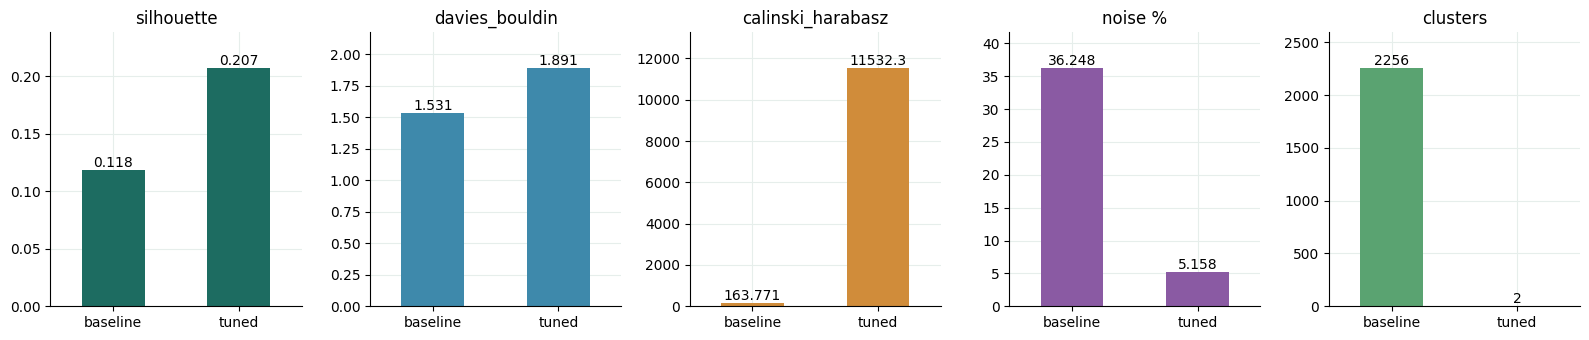

In [56]:
final = HDBSCAN(min_cluster_size=BEST_MIN_CLUSTER_SIZE, min_samples=int(best["min_samples"]),
                copy=True, n_jobs=-1).fit(Xd)

order = pd.Series(final.labels_[final.labels_ >= 0]).value_counts().index   # old cluster ids, largest first
new_id = {old: new for new, old in enumerate(order)}
final.labels_ = np.array([new_id.get(old, -1) for old in final.labels_])     # noise (-1) stays -1
labels = final.labels_
C = [f"C{k}" for k in range(labels.max() + 1)]

comparison = pd.DataFrame([baseline_scores, evaluate(labels)], index=["baseline", "tuned"]).round(3)
axes = comparison[["silhouette", "davies_bouldin", "calinski_harabasz", "noise %", "clusters"]].plot.bar(
    subplots=True, layout=(1, 5), figsize=(16, 3.5), legend=False, rot=0)
for ax in axes.flat:
    ax.bar_label(ax.containers[0])     # value above each bar
    ax.margins(y=0.15)
save("01_baseline_vs_tuned.png")

* The tuned model is better on silhouette and Calinski–Harabasz, and the noise falls from 36.2% to 5.2%.
* Davies–Bouldin is better for the baseline, because its 2,256 tiny clusters are each very tight. but as clusters they describe nothing

## 8 Tuned clusters

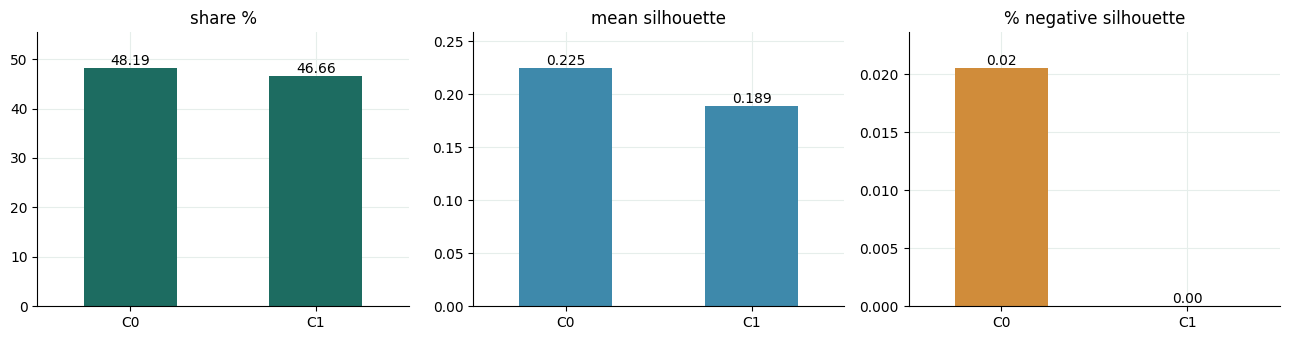

In [57]:
s = S[labels[S] >= 0]                        # silhouette sample without the noise
sil = silhouette_samples(X[s], labels[s])
per_cluster = pd.DataFrame({
    "share %": [(labels == k).mean() * 100 for k in range(len(C))],
    "mean silhouette": [sil[labels[s] == k].mean() for k in range(len(C))],
    "% negative silhouette": [(sil[labels[s] == k] < 0).mean() * 100 for k in range(len(C))],
}, index=C)

axes = per_cluster.plot.bar(subplots=True, layout=(1, 3), figsize=(13, 3.5), legend=False, rot=0)
for ax in axes.flat:
    fmt = "%.3f" if ax.get_title() == "mean silhouette" else "%.2f"
    ax.bar_label(ax.containers[0], fmt=fmt)     # value above each bar
    ax.margins(y=0.15)
save("02_sizes_silhouette.png")

In [58]:
names = C + ["noise"]
group = pd.Series(labels, name="cluster").map(lambda k: f"C{k}" if k >= 0 else "noise")
g = info.groupby(group)
prof = pd.DataFrame({
    "lead time (median days)": g["LeadTime"].median(),
    "nights (median)": g["TotalNights"].median(),
    "guests (mean)": g["TotalGuests"].mean(),
    "ADR (median)": g["ADR"].median(),
    "special requests (mean)": g["TotalOfSpecialRequests"].mean(),
    "repeat guests %": g["IsRepeatedGuest"].mean() * 100,
}).loc[names]
prof.round(1)

,lead time (median days),nights (median),guests (mean),ADR (median),special requests (mean),repeat guests %
cluster,,,,,,
C0,52.0,3.0,2.0,109.6,1.4,2.5
C1,48.0,3.0,1.9,98.1,0.0,2.9
noise,32.0,3.0,3.5,190.0,0.9,2.3


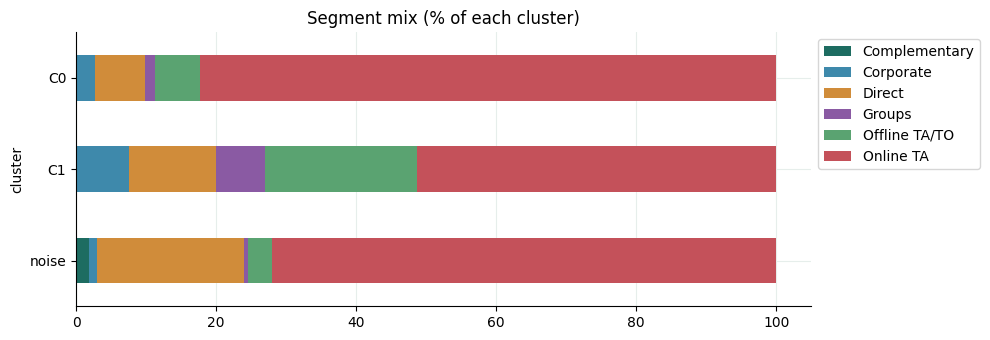

In [59]:
mix = pd.crosstab(group, info["Segment"], normalize="index").loc[names] * 100
mix.plot.barh(stacked=True, figsize=(10, 3.5), title="Segment mix (% of each cluster)")
plt.gca().invert_yaxis()
plt.legend(bbox_to_anchor=(1, 1))
save("03_segment_mix.png")

## 9 PCA view

variance explained by PC1 + PC2: 0.575


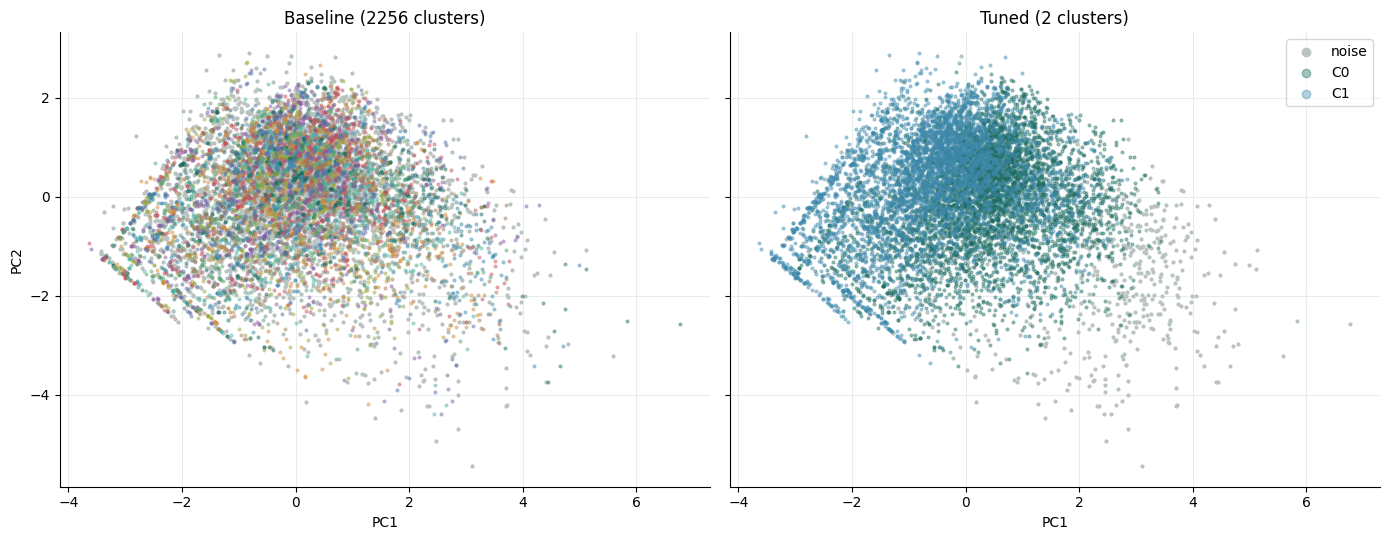

In [60]:
pca = PCA(n_components=2).fit(X)
P = pca.transform(X[S])
print("variance explained by PC1 + PC2:", round(pca.explained_variance_ratio_.sum(), 3))

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), sharex=True, sharey=True)
for ax, model_labels, title in [(axes[0], baseline.labels_, "Baseline"), (axes[1], labels, "Tuned")]:
    lab = model_labels[S]
    ax.scatter(P[lab < 0, 0], P[lab < 0, 1], s=4, color=grey, label="noise")
    for k in range(lab.max() + 1):
        ax.scatter(P[lab == k, 0], P[lab == k, 1], s=4, alpha=0.4, color=COLORS[k % len(COLORS)], label=f"C{k}")
    ax.set_title(f"{title} ({model_labels.max() + 1} clusters)")
    ax.set_xlabel("PC1")
axes[0].set_ylabel("PC2")
axes[1].legend(markerscale=3)
save("04_pca_baseline_vs_tuned.png")

C0 and C1 overlap almost completely in the PCA plane, because they differ mainly in special requests (section 10). The noise sits at the far right, where the large, expensive bookings are.

## 10 How the clusters differ from the average booking

Effect size = (cluster mean − overall mean) / overall standard deviation

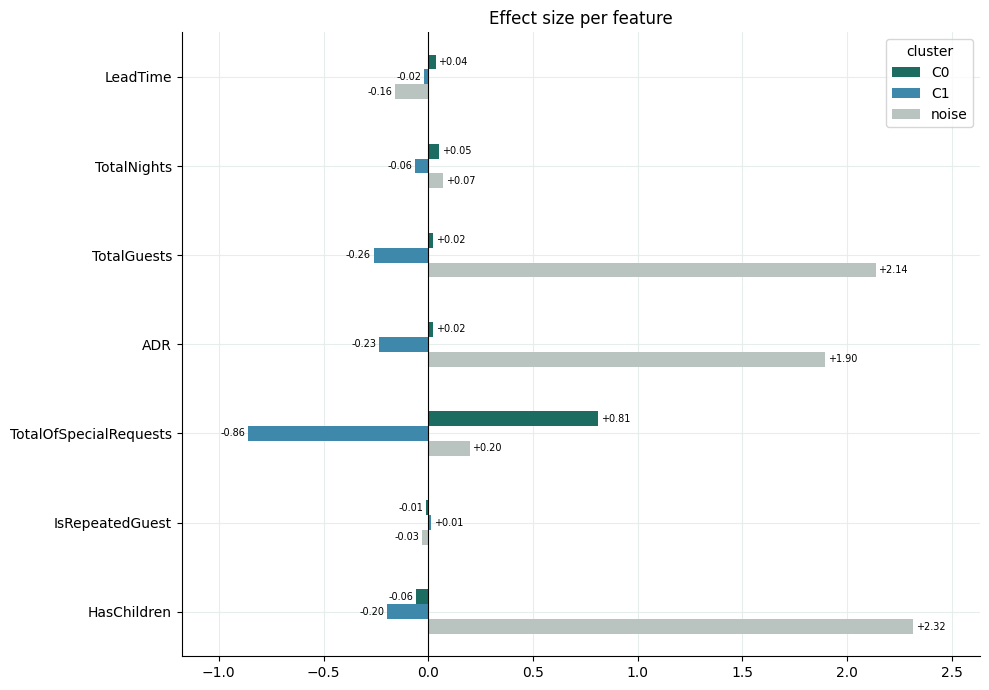

In [61]:
desc = info.copy()
desc["HasChildren"] = ((desc["Children"] + desc["Babies"]) > 0).astype(int)
feats = desc[["LeadTime", "TotalNights", "TotalGuests", "ADR", "TotalOfSpecialRequests", "IsRepeatedGuest", "HasChildren"]]

effect = ((feats.groupby(group).mean() - feats.mean()) / feats.std()).loc[names]
ax = effect.T.plot.barh(figsize=(10, 7), color=COLORS[:len(C)] + [grey], title="Effect size per feature")
for bars in ax.containers:
    ax.bar_label(bars, fmt="%+.2f", fontsize=7, padding=2)   # value at the end of each bar
ax.margins(x=0.1)                                            # room for the labels
plt.axvline(0, color="black", lw=0.8)
plt.gca().invert_yaxis()
save("05_effect_sizes.png")

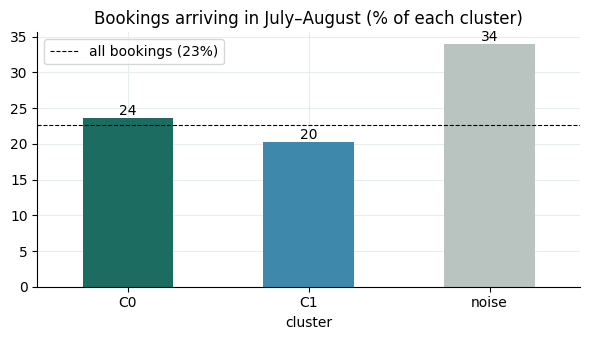

In [62]:
summer = desc["ArrivalDateMonth"].isin(["July", "August"])
share = summer.groupby(group).mean().loc[names] * 100

ax = share.plot.bar(figsize=(6, 3.5), rot=0, color=COLORS[:len(C)] + [grey], title="Bookings arriving in July–August (% of each cluster)")
ax.bar_label(ax.containers[0], fmt="%.0f")     # value above each bar
ax.axhline(summer.mean() * 100, color="black", ls="--", lw=0.8, label=f"all bookings ({summer.mean() * 100:.0f}%)")
ax.legend(handles=ax.lines)     # only the dashed line
save("06_summer_share.png")

| Cluster | Share | Name | Main traits |
|---|---|---|---|
| C0 | 48.2% | Bookings with special requests | 1.4 requests on average, everything else average: 52 days ahead, 3 nights, 2 guests, €110, mostly Online TA |
| C1 | 46.7% | Bookings without special requests | no requests, slightly smaller parties and cheaper (€98), more Offline TA/TO |
| noise | 5.2% | Families and large parties | 3.5 guests, €190, by far the most children, more Direct bookings |

* only one strong split is found: special requests or not. Lead time and length of stay barely differ between C0 and C1.
* The noise is not random: it is the large, expensive family bookings, which are too spread out to be dense.
* Children and arrival month were not used to build the clusters, but they still fit: the noise has by far the most children and the most July–August arrivals (34%, against 23% for all bookings).

## 11 Leakage audit

To check that the clusters are not just a split into "cancels" and "does not cancel" 

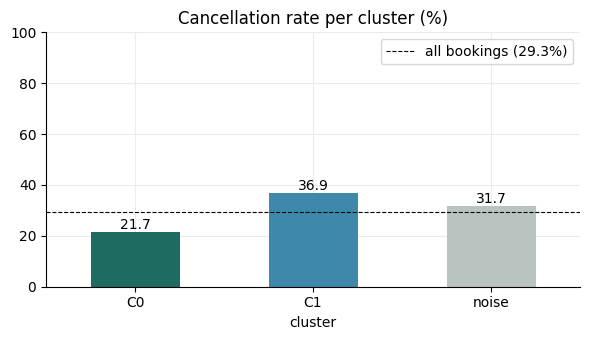

In [63]:
rate = info.groupby(group)["IsCanceled"].mean().loc[names] * 100
overall = info["IsCanceled"].mean() * 100

ax = rate.plot.bar(figsize=(6, 3.5), rot=0, color=COLORS[:len(C)] + [grey], title="Cancellation rate per cluster (%)")
ax.bar_label(ax.containers[0], fmt="%.1f")     # value above each bar
ax.axhline(overall, color="black", ls="--", lw=0.8, label=f"all bookings ({overall:.1f}%)")
ax.set_ylim(0, 100)
ax.legend(handles=ax.lines)     # only the dashed line
save("07_cancellation.png")

Cancellation ranges from 21.7% (C0) to 36.9% (C1), around 29.3% for all bookings. No group is close to 0% or 100%, so the clusters are not a disguised cancellation split and nothing leaked into the inputs. Bookings without special requests cancel more often.

## Save the tuned model

In [64]:
joblib.dump(final, f"{MODEL_DIR}/hdbscan_tuned.joblib")

['model/hdbscan_tuned.joblib']